To get to this point: polygonize ISA_tree_tops (better to use Raster pixels to points) -> fix geometries of crowns_drawn_manually -> Join attributes by location (summary) with crowns_drawn_fixed and polygonized ISA_tree_tops -> save this as CSV with only tree_id and fid_count selected. 

In [2]:
import pandas as pd

errors_df = pd.read_csv('errors_per_tree_heights.csv')
fieldwork_heights = pd.read_csv("lizirias_fieldwork_trees.csv")
errors_df.head(), fieldwork_heights.head()


(  tree_id  height_count  height_max
 0  p205t1           NaN         NaN
 1  p205t2           NaN         NaN
 2  p205t3           NaN         NaN
 3  p205t4           2.0    6.808346
 4  p205t5           1.0    9.025441,
   location_id  plot_id  tree_id  d_cm  perimeter  du_cm  ct_mm  ht_m  hcb_m  \
 0      P175T1      175        1  70.0        NaN    NaN   15.0  12.2    2.0   
 1      P175T2      175        2  47.5        NaN    NaN   10.0   9.0    1.8   
 2      P175T3      175        3  30.8        NaN    NaN    8.0   6.5    1.8   
 3      P175T4      175        4  31.5        NaN    NaN    8.0   8.4    1.5   
 4      P175T5      175        5  15.6        NaN    NaN    NaN   5.9    1.8   
 
        yd    observations  Unnamed: 11 Unnamed: 12  
 0  2023.0             NaN          NaN         NaN  
 1  2023.0             NaN          NaN         NaN  
 2  2023.0             NaN          NaN         NaN  
 3  2023.0             NaN          NaN         NaN  
 4     NaN  Never debarke

In [3]:
omission = errors_df['height_count'].isna().sum()
commission = (errors_df.loc[errors_df['height_count'] > 1, 'height_count'] - 1).sum()

omission, commission

(np.int64(123), np.float64(29.0))

In [4]:
errors_df.count

<bound method DataFrame.count of     tree_id  height_count  height_max
0    p205t1           NaN         NaN
1    p205t2           NaN         NaN
2    p205t3           NaN         NaN
3    p205t4           2.0    6.808346
4    p205t5           1.0    9.025441
..      ...           ...         ...
309  p61t37           1.0    9.810858
310  p61t38           1.0    9.014693
311  p61t39           2.0    8.795735
312  p61t40           1.0    8.757657
313  p61t41           NaN         NaN

[314 rows x 3 columns]>

Commission error is FN/(FN + TP), and omission error is FP/(FP + TP)

In [5]:
tp = (errors_df['height_count'] == 1).sum()

commission_error = commission / (commission + tp)
omission_error = omission / (omission + tp)

commission_error, omission_error, tp

(np.float64(0.14948453608247422),
 np.float64(0.4270833333333333),
 np.int64(165))

The omission error is high, but the small trees below 2m still need to be excluded. Some of these were drawn because we collected their GPS points in the field, however the method to find the tree tops excludes any plants below 2m. The commission error is quite low, however the large trees are the ones that have multiple points detected, and so this will overestimate the amount of large trees while estimating the medium and small (above 2m) trees well. This will present an issue if using this data for subsequent modelling, such as biomass predictions. 
Note: these calculations were over all 12 plots, as it did not use these plots to train a model, so they could all be used for validation. 

Next: exclude polygons under 2m? Should check this value with supervisors. Though some in clusters of canopies, such as p14t12, are omissions. 
Next: plot max of heights (or should all points be plotted, as these will be what users use on non-polygonned crowns) for each polygon, compared to fieldwork heights.
Next: make pipeline from image submission to heights and tree counts. 

In [6]:
fieldwork_heights = fieldwork_heights[['location_id', 'ht_m']]
print(fieldwork_heights.head())

  location_id  ht_m
0      P175T1  12.2
1      P175T2   9.0
2      P175T3   6.5
3      P175T4   8.4
4      P175T5   5.9


In [7]:
fieldwork_heights['location_id'] = fieldwork_heights['location_id'].str.lower()
fieldwork_heights = fieldwork_heights.rename(columns={'location_id': 'tree_id'})
fieldwork_heights.head()

,tree_id,ht_m
0,p175t1,12.2
1,p175t2,9.0
2,p175t3,6.5
3,p175t4,8.4
4,p175t5,5.9


In [8]:
merged_heights = pd.merge(errors_df, fieldwork_heights, on='tree_id', how='inner')
merged_heights.head()

,tree_id,height_count,height_max,ht_m
0,p205t1,NaN,NaN,2.7
1,p205t2,NaN,NaN,3.3
2,p205t3,NaN,NaN,4.0
3,p205t4,2.0,6.808346,3.8
4,p205t5,1.0,9.025441,8.9


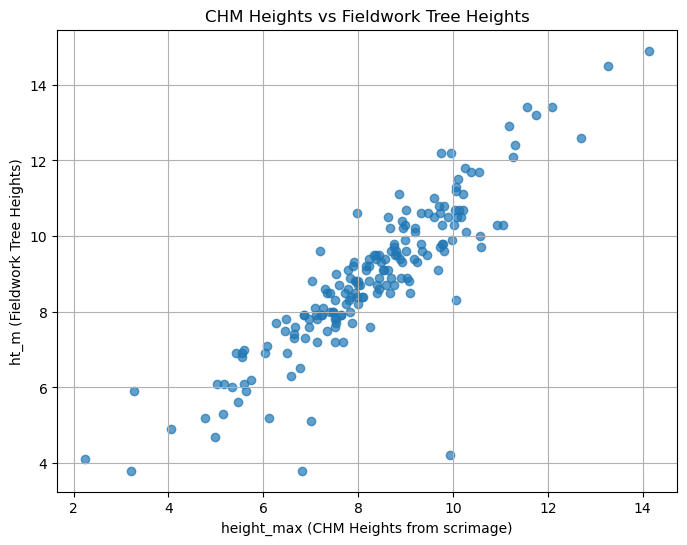

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(merged_heights['height_max'], merged_heights['ht_m'], alpha=0.7)
plt.xlabel('height_max (CHM Heights from scrimage)')
plt.ylabel('ht_m (Fieldwork Tree Heights)')
plt.title('CHM Heights vs Fieldwork Tree Heights')
plt.grid(True)
plt.show()

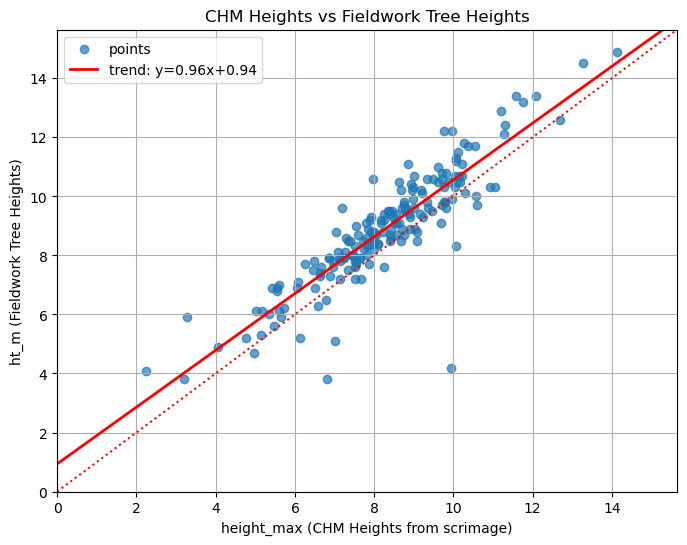

In [10]:
import numpy as np

df = merged_heights.dropna(subset=['height_max', 'ht_m'])
x = df['height_max'].values
y = df['ht_m'].values

slope, intercept = np.polyfit(x, y, 1)
max_axis = max(x.max(), y.max()) * 1.05
x_line = np.linspace(0, max_axis, 100)
y_line = slope * x_line + intercept

plt.figure(figsize=(8, 6))
plt.scatter(x, y, alpha=0.7, label='points')
plt.plot(x_line, y_line, color='red', lw=2, label=f'trend: y={slope:.2f}x+{intercept:.2f}')
plt.axline((0, 0), slope=1, color='red', linestyle=':')
plt.xlabel('height_max (CHM Heights from scrimage)')
plt.ylabel('ht_m (Fieldwork Tree Heights)')
plt.title('CHM Heights vs Fieldwork Tree Heights')
plt.xlim(0, max_axis)
plt.ylim(0, max_axis)
plt.grid(True)
plt.legend()
plt.show()

This shows only the maximum point in each polygon. The fieldwork heights are slightly above the CHM heights, however the UAV image was taken 2 years before the heights were measured, so this makes sense assuming the trees grew during those two years. 

Questions for João and Sofia
- Is 2m a good height to start at (i.e. what height to foresters start measuring trees?)
- Where there are commission errors on large trees, should I plot both points, or only one point?
- Is this what is wanted for the first paper? Just comparing field heights to UAV heights, or comparing field heights to heighest points as a predicted tree (more practical for real world use but has omission/commission errors)
- Should pipeline give per hectare, per tree, or whole image tree counts and heights?

Next: pipeline from uploading image to giving tree count and heights (per hectare?)

In [11]:
rmse = np.sqrt(np.mean((df["height_max"] - df["ht_m"]) ** 2))
rmse

np.float64(1.0848413813026263)

In [ ]:
filtered_df = merged_heights.dropna(subset=['ht_m', 'height_max'])
filtered_df.head()

,tree_id,height_count,height_max,ht_m
3,p205t4,2.0,6.808346,3.8
4,p205t5,1.0,9.025441,8.9
5,p205t6,1.0,7.855484,8.4
6,p205t7,1.0,7.647242,7.9
7,p205t8,1.0,5.587666,7.0


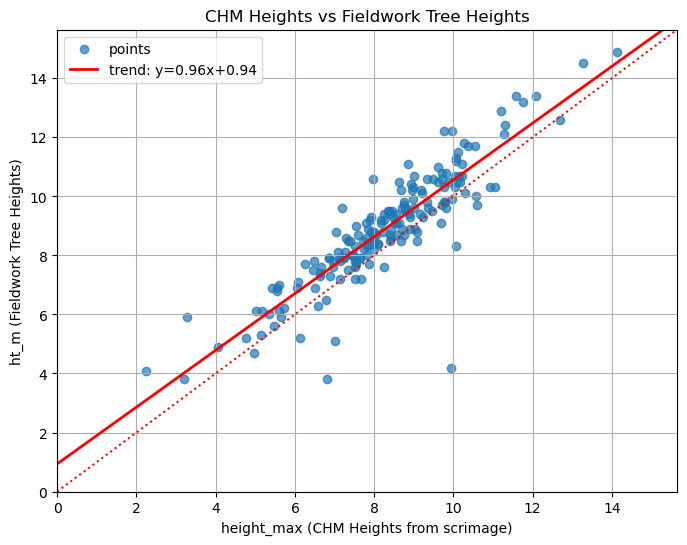

In [13]:
df = filtered_df.dropna(subset=['height_max', 'ht_m'])
x = df['height_max'].values
y = df['ht_m'].values

slope, intercept = np.polyfit(x, y, 1)
max_axis = max(x.max(), y.max()) * 1.05
x_line = np.linspace(0, max_axis, 100)
y_line = slope * x_line + intercept

plt.figure(figsize=(8, 6))
plt.scatter(x, y, alpha=0.7, label='points')
plt.plot(x_line, y_line, color='red', lw=2, label=f'trend: y={slope:.2f}x+{intercept:.2f}')
plt.axline((0, 0), slope=1, color='red', linestyle=':')
plt.xlabel('height_max (CHM Heights from scrimage)')
plt.ylabel('ht_m (Fieldwork Tree Heights)')
plt.title('CHM Heights vs Fieldwork Tree Heights')
plt.xlim(0, max_axis)
plt.ylim(0, max_axis)
plt.grid(True)
plt.legend()
plt.show()

In [16]:
print(len(y), len(y_line))

183 100


In [14]:
from sklearn.metrics import r2_score

r2 = r2_score(y, y_line)
r2

ValueError: Found input variables with inconsistent numbers of samples: [183, 100]

In [1]:
print('hello')

hello
